# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** Fatimatus Zahroh  
**NIM:** 202310370311271  
**Username GitHub:** fatimatus101  

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [3]:

from pathlib import Path

import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def find_project_root(start=None):
    """Naik ke folder induk sampai menemukan folder data/ dan notebooks/."""
    start = (start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data").is_dir() and (folder / "notebooks").is_dir():
            return folder
    return start


PROJECT_ROOT = find_project_root()
path_data = PROJECT_ROOT / "data" / "processed" / "dataset_bersih.parquet"
FIGURES_DIR = PROJECT_ROOT / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not path_data.exists():
    raise FileNotFoundError(
        f"Data bersih tidak ditemukan: {path_data}. Jalankan 02_data_cleaning.ipynb terlebih dahulu."
    )

df = pl.read_parquet(path_data)
print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")

# DuckDB membaca DataFrame Polars yang sama (tanpa menyalin ke file)
con = duckdb.connect()
con.register("data_bersih", df)


def tampilkan(fig, nama):
    """Tampilkan grafik interaktif dan simpan sebagai HTML di output/figures/."""
    fig.update_layout(template="plotly_white", margin=dict(t=80, l=60, r=30, b=60))
    fig.show()
    fig.write_html(str(FIGURES_DIR / f"{nama}.html"), include_plotlyjs="cdn")


def kelompok(kolom, batas, label):
    """Mengelompokkan nilai numerik ke label berdasarkan batas atas (eksklusif)."""
    ekspresi = pl.when(pl.col(kolom) < batas[0]).then(pl.lit(label[0]))
    for b, l in zip(batas[1:], label[1:-1]):
        ekspresi = ekspresi.when(pl.col(kolom) < b).then(pl.lit(l))
    return ekspresi.otherwise(pl.lit(label[-1]))



Data loaded: 1,025,801 baris x 26 kolom



**Pemeriksaan asumsi grid.** Analisis riwayat per titik mensyaratkan bahwa setiap titik (`lon`, `lat`) teramati pada **semua** tanggal kejadian. Pemeriksaan berikut memastikannya.


In [4]:

jumlah_tanggal = df["date"].n_unique()
pengamatan_per_titik = df.group_by("lon", "lat").agg(pl.len().alias("n_tanggal"))["n_tanggal"].unique().to_list()

print(f"Jumlah tanggal kejadian : {jumlah_tanggal}")
print(f"Pengamatan per titik    : {pengamatan_per_titik}")
assert pengamatan_per_titik == [jumlah_tanggal], "Grid titik tidak sama pada semua tanggal"
print("Grid titik identik pada seluruh tanggal.")


Jumlah tanggal kejadian : 7
Pengamatan per titik    : [7]
Grid titik identik pada seluruh tanggal.


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions)
untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

Karena data hanya berisi 7 tanggal kejadian, analisis temporal dilakukan pada dua tingkat: **(a)** antar kejadian (agregasi seluruh grid), dan **(b)** riwayat tiap titik antar kejadian (apakah titik yang pernah banjir cenderung banjir lagi).


### a. Agregasi per kejadian dengan `group_by_dynamic` (Polars)

In [5]:

df_temporal = (
    df.sort("date")
    .group_by_dynamic("date", every="1mo")           # jendela waktu bulanan
    .agg(
        pl.col("date").min().alias("tanggal_kejadian"),
        pl.len().alias("n_titik"),
        pl.col("target").sum().alias("titik_banjir"),
        (pl.col("target").mean() * 100).alias("rasio_banjir_pct"),
        pl.col("precip_1d").mean().alias("rata_hujan_1d"),
        pl.col("precip_3d").mean().alias("rata_hujan_3d"),
        pl.col("NDVI_scaled").mean().alias("rata_ndvi"),
    )
    .drop("date")
    .sort("tanggal_kejadian")
)
df_temporal


tanggal_kejadian,n_titik,titik_banjir,rasio_banjir_pct,rata_hujan_1d,rata_hujan_3d,rata_ndvi
date,u32,i64,f64,f64,f64,f64
2003-12-10,146543,17333,11.827928,11.475199,62.850881,0.529655
2004-05-07,146543,8190,5.588803,16.438275,30.301756,0.61405
2006-06-19,146543,1718,1.172352,7.718537,43.882215,0.621202
2007-06-16,146543,7100,4.844994,1.936977,39.478446,0.640246
2007-07-25,146543,5295,3.613274,6.88409,25.781169,0.612868
2013-01-03,146543,2805,1.914114,17.762995,57.099094,0.561329
2015-02-05,146543,3914,2.670888,21.075226,39.628155,0.617366


### b. `shift`, `diff`, `rolling_mean`, dan `cum_sum` antar kejadian (Polars)
Ringkasan per kejadian dilengkapi selisih dengan kejadian sebelumnya, rata-rata bergerak 2 kejadian, peringkat, dan jumlah titik banjir kumulatif.

In [6]:

df_peristiwa = df_temporal.with_columns(
    pl.col("tanggal_kejadian").dt.strftime("%Y-%m-%d (%b)").alias("label_kejadian"),
    pl.col("tanggal_kejadian").diff().dt.total_days().alias("selang_hari"),
    pl.col("rasio_banjir_pct").shift(1).alias("rasio_sebelumnya_pct"),
    pl.col("rasio_banjir_pct").diff().alias("perubahan_rasio_pct"),
    pl.col("rasio_banjir_pct").rolling_mean(window_size=2).alias("rata_bergerak_2_kejadian"),
    pl.col("rasio_banjir_pct").rank("ordinal", descending=True).alias("peringkat_rasio"),
    pl.col("titik_banjir").cum_sum().alias("banjir_kumulatif"),
)
df_peristiwa.select(
    "label_kejadian", "titik_banjir", "rasio_banjir_pct", "selang_hari",
    "perubahan_rasio_pct", "rata_bergerak_2_kejadian", "peringkat_rasio", "banjir_kumulatif",
)


label_kejadian,titik_banjir,rasio_banjir_pct,selang_hari,perubahan_rasio_pct,rata_bergerak_2_kejadian,peringkat_rasio,banjir_kumulatif
str,i64,f64,i64,f64,f64,u32,i64
"""2003-12-10 (Dec)""",17333,11.827928,null,null,null,1,17333
"""2004-05-07 (May)""",8190,5.588803,149,-6.239124,8.708365,2,25523
"""2006-06-19 (Jun)""",1718,1.172352,773,-4.416451,3.380578,7,27241
"""2007-06-16 (Jun)""",7100,4.844994,362,3.672642,3.008673,3,34341
"""2007-07-25 (Jul)""",5295,3.613274,39,-1.23172,4.229134,4,39636
"""2013-01-03 (Jan)""",2805,1.914114,1989,-1.69916,2.763694,6,42441
"""2015-02-05 (Feb)""",3914,2.670888,763,0.756774,2.292501,5,46355



### c. Window function SQL di DuckDB (`LAG`, `SUM OVER`, `RANK`, `ROWS BETWEEN`)
Perhitungan yang sama dilakukan dengan SQL sebagai pembanding, lalu hasilnya diverifikasi terhadap Polars.


In [7]:

window_sql = con.sql("""
    WITH per_tanggal AS (
        SELECT date,
               CAST(SUM(target) AS BIGINT) AS titik_banjir,
               100.0 * AVG(target)         AS rasio_pct,
               AVG(precip_3d)              AS hujan_3d
        FROM data_bersih
        GROUP BY date
    )
    SELECT date,
           titik_banjir,
           ROUND(rasio_pct, 2)                                               AS rasio_pct,
           ROUND(rasio_pct - LAG(rasio_pct) OVER (ORDER BY date), 2)        AS selisih_vs_sebelumnya,
           CAST(SUM(titik_banjir) OVER (ORDER BY date) AS BIGINT)           AS banjir_kumulatif,
           RANK() OVER (ORDER BY rasio_pct DESC)                            AS peringkat,
           ROUND(AVG(rasio_pct) OVER (ORDER BY date ROWS BETWEEN 1 PRECEDING AND CURRENT ROW), 2) AS rata_bergerak_2_kejadian
    FROM per_tanggal
    ORDER BY date
""").pl()

# Verifikasi silang: hasil SQL harus sama dengan Polars
assert window_sql["titik_banjir"].to_list() == df_peristiwa["titik_banjir"].to_list()
assert window_sql["banjir_kumulatif"].to_list() == df_peristiwa["banjir_kumulatif"].to_list()
assert window_sql["peringkat"].to_list() == df_peristiwa["peringkat_rasio"].to_list()
print("Hasil window function DuckDB sama dengan Polars.")
window_sql


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Hasil window function DuckDB sama dengan Polars.


date,titik_banjir,rasio_pct,selisih_vs_sebelumnya,banjir_kumulatif,peringkat,rata_bergerak_2_kejadian
date,i64,f64,f64,i64,i64,f64
2003-12-10,17333,11.83,null,17333,1,11.83
2004-05-07,8190,5.59,-6.24,25523,2,8.71
2006-06-19,1718,1.17,-4.42,27241,7,3.38
2007-06-16,7100,4.84,3.67,34341,3,3.01
2007-07-25,5295,3.61,-1.23,39636,4,4.23
2013-01-03,2805,1.91,-1.7,42441,6,2.76
2015-02-05,3914,2.67,0.76,46355,5,2.29



### d. Riwayat per titik
Data diurutkan menurut tanggal, lalu `shift(1).over(["lon", "lat"])` mengambil status banjir titik yang sama pada kejadian sebelumnya (window function per kelompok). Peluang banjir dibandingkan menurut status sebelumnya.


In [8]:

df_urut = df.sort("date").with_columns(
    pl.col("target").shift(1).over(["lon", "lat"]).alias("target_sebelumnya")
)

persistensi = (
    df_urut.filter(pl.col("target_sebelumnya").is_not_null())
    .group_by("target_sebelumnya")
    .agg(
        pl.len().alias("n_transisi"),
        pl.col("target").sum().alias("banjir_berikutnya"),
        (pl.col("target").mean() * 100).alias("peluang_banjir_pct"),
    )
    .sort("target_sebelumnya")
)
persistensi


target_sebelumnya,n_transisi,banjir_berikutnya,peluang_banjir_pct
i8,u32,i64,f64
0,836817,12570,1.502121
1,42441,16452,38.764402


### e. Frekuensi banjir per titik (dari 7 kejadian)

In [9]:

rekurensi = df.group_by("lon", "lat").agg(pl.col("target").sum().alias("kejadian_banjir"))

dist_rekurensi = (
    rekurensi.group_by("kejadian_banjir").agg(pl.len().alias("n_titik"))
    .sort("kejadian_banjir")
    .with_columns((pl.col("n_titik") / pl.col("n_titik").sum() * 100).alias("persen_titik"))
)
dist_rekurensi


kejadian_banjir,n_titik,persen_titik
i64,u32,f64
0,126660,86.431969
1,9298,6.344895
2,3539,2.414991
3,2550,1.740104
4,1859,1.26857
5,1289,0.879605
6,988,0.674205
7,360,0.245662



### f. Hubungan antara hujan rata-rata dan luas banjir antar kejadian
Korelasi peringkat (Spearman) antara rata-rata hujan 3 hari dan rasio banjir pada 7 kejadian. 


In [10]:

rho_hujan_banjir = df_peristiwa.select(
    pl.corr("rata_hujan_3d", "rasio_banjir_pct", method="spearman")
).item()
print(f"Korelasi Spearman (hujan 3 hari vs rasio banjir, n=7 kejadian): {rho_hujan_banjir:.2f}")


Korelasi Spearman (hujan 3 hari vs rasio banjir, n=7 kejadian): -0.11


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

### Visualisasi 1: Tren per kejadian (line chart dengan range slider)

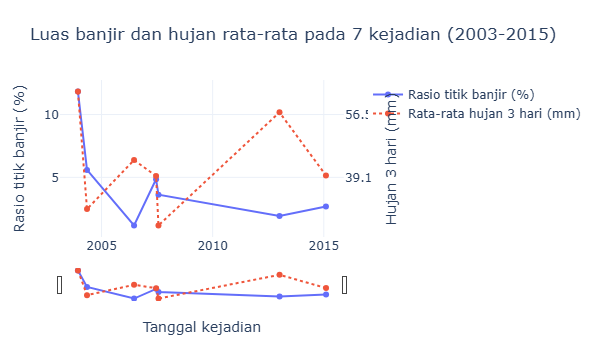

In [11]:

x_kejadian = df_peristiwa["tanggal_kejadian"].to_list()

fig1 = make_subplots(specs=[[{"secondary_y": True}]])
fig1.add_trace(go.Scatter(
    x=x_kejadian, y=df_peristiwa["rasio_banjir_pct"].to_list(), mode="lines+markers",
    name="Rasio titik banjir (%)", customdata=df_peristiwa["titik_banjir"].to_list(),
    hovertemplate="%{x|%d %b %Y}<br>Rasio banjir: %{y:.2f}%<br>Titik banjir: %{customdata:,}<extra></extra>",
), secondary_y=False)
fig1.add_trace(go.Scatter(
    x=x_kejadian, y=df_peristiwa["rata_hujan_3d"].to_list(), mode="lines+markers",
    name="Rata-rata hujan 3 hari (mm)", line=dict(dash="dot"),
    hovertemplate="%{x|%d %b %Y}<br>Hujan 3 hari: %{y:.1f} mm<extra></extra>",
), secondary_y=True)
fig1.update_xaxes(rangeslider_visible=True, title_text="Tanggal kejadian")
fig1.update_yaxes(title_text="Rasio titik banjir (%)", secondary_y=False)
fig1.update_yaxes(title_text="Hujan 3 hari (mm)", secondary_y=True)
fig1.update_layout(title="Luas banjir dan hujan rata-rata pada 7 kejadian (2003-2015)")
tampilkan(fig1, "eda_01_tren_per_kejadian")


Kejadian pertama (akhir 2003/awal 2004) mencatatkan luasan banjir paling tinggi dengan rasio 11,83% (sekitar 17.333 titik banjir), yaitu sekitar 2,1 kali lipat dari kejadian terbesar kedua dan 10 kali lipat dibanding kejadian terkecil (sekitar pertengahan 2006 dengan rasio 1,17%). Rasio luas banjir dan rata-rata hujan 3 hari tidak menunjukkan pergerakan yang searah. Sebagai contoh, kejadian di awal tahun 2013 memiliki rata-rata hujan 3 harian tertinggi (sekitar 56,5–57,1 mm), namun rasio banjirnya relatif rendah (hanya 1,91%).Nilai korelasi peringkat Spearman antara kedua variabel bernilai -0,11 ($n = 7$), yang mengindikasikan tidak adanya hubungan monotonik yang kuat antara rata-rata hujan 3 hari dengan luas banjir pada level agregat kejadian ini. Perlu dicatat bahwa grafik ini dievaluasi hanya dari 7 titik waktu kejadian utama.

### Visualisasi 2: Distribusi variabel utama menurut label banjir (box plot dengan pilihan variabel)

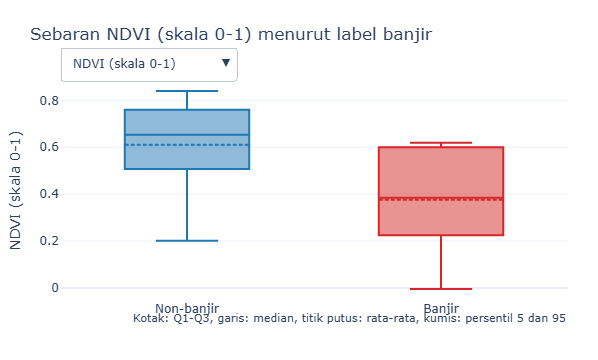

In [12]:

VAR_BOX = {
    "NDVI_scaled": "NDVI (skala 0-1)",
    "NDWI": "NDWI",
    "TWI": "TWI",
    "precip_1d": "Hujan 1 hari (mm)",
    "precip_3d": "Hujan 3 hari (mm)",
    "elevation": "Elevasi (m)",
    "slope": "Kemiringan (derajat)",
    "upstream_area_log": "log1p(upstream_area)",
}
KUANTIL = [(0.05, "p05"), (0.25, "q1"), (0.5, "med"), (0.75, "q3"), (0.95, "p95")]

# Statistik kotak dihitung di Polars, sehingga grafik tidak membawa satu juta titik
stat_box = (
    df.group_by("target")
    .agg(
        [pl.col(v).quantile(q).alias(f"{v}__{n}") for v in VAR_BOX for q, n in KUANTIL]
        + [pl.col(v).mean().alias(f"{v}__mean") for v in VAR_BOX]
    )
    .sort("target")
)
NAMA_KELAS = {0: "Non-banjir", 1: "Banjir"}
WARNA_KELAS = {0: "#1f77b4", 1: "#d62728"}

fig2 = go.Figure()
for i, (v, judul) in enumerate(VAR_BOX.items()):
    for t in (0, 1):
        r = stat_box.filter(pl.col("target") == t).row(0, named=True)
        fig2.add_trace(go.Box(
            x=[NAMA_KELAS[t]], name=NAMA_KELAS[t], marker_color=WARNA_KELAS[t],
            q1=[r[f"{v}__q1"]], median=[r[f"{v}__med"]], q3=[r[f"{v}__q3"]],
            lowerfence=[r[f"{v}__p05"]], upperfence=[r[f"{v}__p95"]], mean=[r[f"{v}__mean"]],
            boxmean=True, visible=(i == 0),
        ))

tombol = []
for i, (v, judul) in enumerate(VAR_BOX.items()):
    visibilitas = [j == i for j in range(len(VAR_BOX)) for _ in (0, 1)]
    tombol.append(dict(label=judul, method="update",
                       args=[{"visible": visibilitas}, {"yaxis": {"title": judul}, "title": f"Sebaran {judul} menurut label banjir"}]))

fig2.update_layout(
    title="Sebaran NDVI (skala 0-1) menurut label banjir",
    yaxis_title="NDVI (skala 0-1)", showlegend=False,
    updatemenus=[dict(buttons=tombol, direction="down", x=0.0, y=1.15, xanchor="left")],
)
fig2.add_annotation(text="Kotak: Q1-Q3, garis: median, titik putus: rata-rata, kumis: persentil 5 dan 95",
                    xref="paper", yref="paper", x=1, y=-0.12, showarrow=False, xanchor="right", font=dict(size=11))
tampilkan(fig2, "eda_02_distribusi_boxplot")


### Visualisasi 3: Korelasi antar-variabel numerik (heatmap)

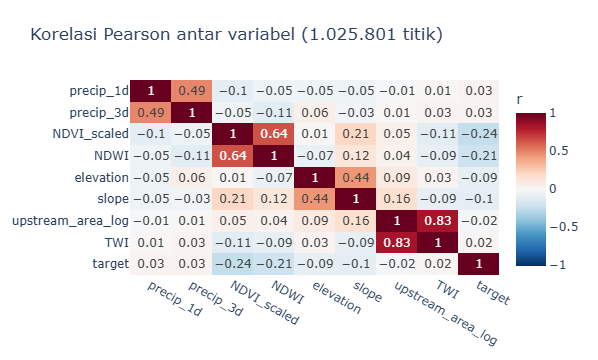

In [13]:

KOLOM_KORELASI = ["precip_1d", "precip_3d", "NDVI_scaled", "NDWI", "elevation",
                  "slope", "upstream_area_log", "TWI", "target"]
korelasi = df.select(KOLOM_KORELASI).corr()
matriks = [[round(v, 2) for v in baris] for baris in korelasi.rows()]

fig3 = px.imshow(
    matriks, x=KOLOM_KORELASI, y=KOLOM_KORELASI, text_auto=True, aspect="auto",
    color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
    title="Korelasi Pearson antar variabel (1.025.801 titik)",
)
fig3.update_layout(coloraxis_colorbar_title="r")
tampilkan(fig3, "eda_03_korelasi")


Korelasi terkuat dengan target ditunjukkan oleh NDVI_scaled ($r = -0,24$) dan NDWI ($r = -0,21$), disusul oleh kemiringan/slope ($-0,10$) dan elevasi ($-0,09$). Sebaliknya, curah hujan hampir tidak menunjukkan korelasi linear dengan label ($r = 0,03$). Kecilnya nilai $\vert{}r\vert{}$ pada seluruh variabel disebabkan oleh sifat target yang berupa data biner dengan kelas banjir yang jarang (rare event) serta pola hubungan yang bersifat non-linear (adanya efek ambang batas pada elevasi dan kemiringan), sehingga angka korelasi linear yang rendah ini tidak menyimpulkan bahwa variabel-variabel tersebut tidak penting. Variabel aspect, flooded, dan jrc_perm_water tidak diikutsertakan karena aspect bernilai 0 untuk menandai area datar, sementara dua kolom lainnya merupakan bagian dari definisi target itu sendiri.

### Visualisasi 4: Komposisi tutupan lahan (bar chart dengan rasio banjir)

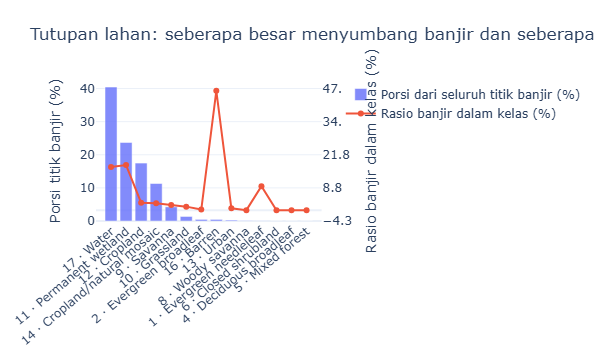

In [15]:
# Nama kelas mengikuti skema IGBP MODIS 
NAMA_LANDCOVER = {
    1: "Evergreen needleleaf", 2: "Evergreen broadleaf", 3: "Deciduous needleleaf", 4: "Deciduous broadleaf",
    5: "Mixed forest", 6: "Closed shrubland", 7: "Open shrubland", 8: "Woody savanna", 9: "Savanna",
    10: "Grassland", 11: "Permanent wetland", 12: "Cropland", 13: "Urban", 14: "Cropland/natural mosaic",
    15: "Snow/ice", 16: "Barren", 17: "Water",
}

komposisi = (
    df.group_by("landcover")
    .agg(
        pl.len().alias("n_titik"),
        pl.col("target").sum().alias("titik_banjir"),
        (pl.col("target").mean() * 100).alias("rasio_pct"),
    )
    .with_columns((pl.col("titik_banjir") / pl.col("titik_banjir").sum() * 100).alias("porsi_banjir_pct"))
    .sort("titik_banjir", descending=True)
)
baris = komposisi.to_dicts()
label_x = [f"{b['landcover']} · {NAMA_LANDCOVER.get(b['landcover'], '?')}" for b in baris]

fig4 = make_subplots(specs=[[{"secondary_y": True}]])
fig4.add_trace(go.Bar(
    x=label_x, y=[b["porsi_banjir_pct"] for b in baris], name="Porsi dari seluruh titik banjir (%)",
    customdata=[[b["n_titik"], b["titik_banjir"]] for b in baris], opacity=0.8,
    hovertemplate="%{x}<br>Porsi titik banjir: %{y:.1f}%<br>Titik: %{customdata[0]:,}<br>Titik banjir: %{customdata[1]:,}<extra></extra>",
), secondary_y=False)
fig4.add_trace(go.Scatter(
    x=label_x, y=[b["rasio_pct"] for b in baris], name="Rasio banjir dalam kelas (%)", mode="lines+markers",
    hovertemplate="%{x}<br>Rasio banjir: %{y:.2f}%<extra></extra>",
), secondary_y=True)
fig4.update_yaxes(title_text="Porsi titik banjir (%)", secondary_y=False)
fig4.update_yaxes(title_text="Rasio banjir dalam kelas (%)", secondary_y=True)
fig4.update_layout(title="Tutupan lahan: seberapa besar menyumbang banjir dan seberapa rawan", xaxis_tickangle=-40)
tampilkan(fig4, "eda_04_tutupan_lahan")


Berdasarkan analisis tutupan lahan, tiga kelas utama yaitu kelas 17 (Water), 11 (Permanent wetland), dan 12 (Cropland) secara kumulatif menyumbang 81,7% dari seluruh titik banjir. Rasio kerawanan banjir tertinggi tercatat pada kelas 11 (17,79%) dan kelas 17 (17,06%). Sebaliknya, kelas 2 (83.259 titik) dan kelas 8 (142.053 titik) hampir tidak pernah mengalami banjir, masing-masing dengan rasio 0,27% dan 0,03%. Meskipun kelas 16 (Barren) memiliki rasio yang tampak tinggi yaitu 47,03%, kelas ini hanya mencakup 472 titik sehingga statistiknya kurang representatif. Di sisi lain, Cropland memiliki rasio yang relatif rendah (2,94%) namun memuat 275.882 titik, menjadikannya penyumbang volume absolut yang sangat besar. Penamaan kelas ini mengacu pada skema standar IGBP MODIS sebagai asumsi awal yang tetap perlu diverifikasi melalui dokumentasi sumber data.

### Visualisasi 5: Perbandingan kelompok, rasio banjir tiap kejadian menurut band elevasi (heatmap)

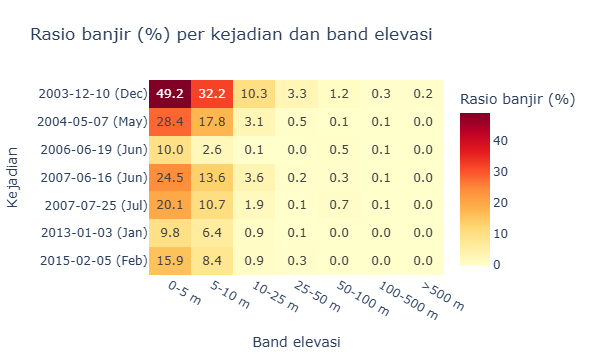

In [16]:

BATAS_ELEVASI = [5, 10, 25, 50, 100, 500]
LABEL_ELEVASI = ["0-5 m", "5-10 m", "10-25 m", "25-50 m", "50-100 m", "100-500 m", ">500 m"]

df_band = df.with_columns(kelompok("elevation", BATAS_ELEVASI, LABEL_ELEVASI).alias("band_elevasi"))

per_band = (
    df_band.group_by("date", "band_elevasi")
    .agg((pl.col("target").mean() * 100).alias("rasio_pct"), pl.len().alias("n_titik"))
)
lookup = {(r["date"], r["band_elevasi"]): r["rasio_pct"] for r in per_band.to_dicts()}
label_y = df_peristiwa["label_kejadian"].to_list()
tanggal_y = df_peristiwa["tanggal_kejadian"].to_list()
z = [[lookup[(d, b)] for b in LABEL_ELEVASI] for d in tanggal_y]

fig5 = go.Figure(go.Heatmap(
    z=z, x=LABEL_ELEVASI, y=label_y, colorscale="YlOrRd", colorbar=dict(title="Rasio banjir (%)"),
    text=[[f"{v:.1f}" for v in baris_z] for baris_z in z], texttemplate="%{text}",
    hovertemplate="Kejadian %{y}<br>Elevasi %{x}<br>Rasio banjir: %{z:.2f}%<extra></extra>",
))
fig5.update_layout(title="Rasio banjir (%) per kejadian dan band elevasi", xaxis_title="Band elevasi", yaxis_title="Kejadian",
                   yaxis=dict(autorange="reversed"))
tampilkan(fig5, "eda_05_kejadian_vs_elevasi")


Berdasarkan analisis ketujuh kejadian banjir, rasio genangan tertinggi secara konsisten selalu terkonsentrasi pada rentang elevasi 0–5 m dan mengalami penurunan tajam seiring dengan bertambahnya ketinggian, hingga mencapai titik terendah (maksimal 0,27%) pada elevasi di atas 100 m. Meskipun pola kerawanan menurut elevasi ini menunjukkan tren yang stabil di setiap kejadian, skala atau besaran luas genangannya bervariasi; pada rentang elevasi 0–5 m, rasio banjir berkisar dari yang terendah sebesar 9,8% pada 3 Januari 2013 hingga mencapai 49,2% pada 10 Desember 2003. Penurunan rasio terhadap elevasi tidak sepenuhnya berjalan mulus (hanya tercatat pada 2 dari 7 kejadian yang turun secara monoton), di mana fluktuasi kecil pada elevasi tinggi utamanya bersumber dari nilai-nilai data yang sudah mendekati angka nol.

### Visualisasi 6: Pola spasial, rasio banjir per sel 0,05° (± 5,5 km)

Jumlah sel: 1,567 | titik per sel (min/median/maks): 7 / 287 / 2513


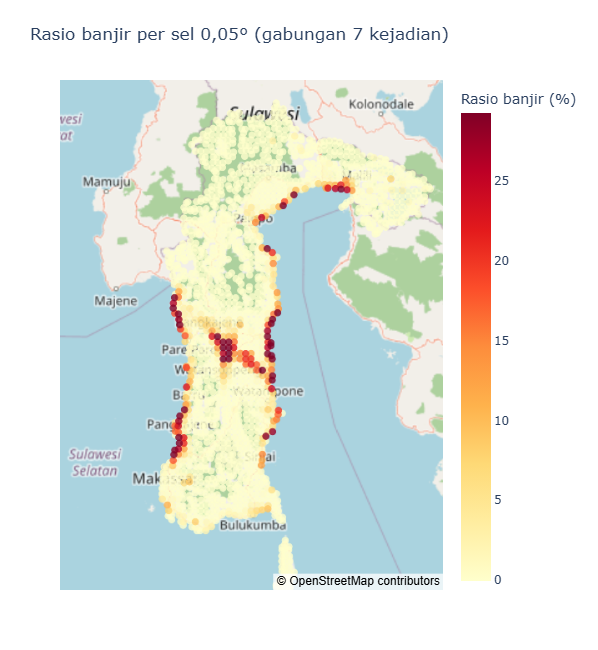

In [17]:

UKURAN_SEL = 0.05   # derajat, sekitar 5,5 km

sel = (
    df.with_columns(
        ((pl.col("lon") / UKURAN_SEL).floor() * UKURAN_SEL).alias("sel_lon"),
        ((pl.col("lat") / UKURAN_SEL).floor() * UKURAN_SEL).alias("sel_lat"),
    )
    .group_by("sel_lon", "sel_lat")
    .agg(
        pl.len().alias("n_titik"),
        pl.col("target").sum().alias("titik_banjir"),
        (pl.col("target").mean() * 100).alias("rasio_pct"),
        pl.col("lon").mean().alias("lon"),
        pl.col("lat").mean().alias("lat"),
    )
    .sort("rasio_pct")           # sel rawan digambar paling akhir 
)
print(f"Jumlah sel: {sel.height:,} | titik per sel (min/median/maks): "
      f"{sel['n_titik'].min()} / {sel['n_titik'].median():.0f} / {sel['n_titik'].max()}")

data_sel = sel.to_dict(as_series=False)
batas_warna = float(sel["rasio_pct"].quantile(0.98))
pusat = dict(lat=float(df["lat"].mean()), lon=float(df["lon"].mean()))

if hasattr(px, "scatter_map"):
    fig6 = px.scatter_map(
        data_sel, lat="lat", lon="lon", color="rasio_pct", color_continuous_scale="YlOrRd",
        range_color=[0, batas_warna], hover_data={"n_titik": ":,", "titik_banjir": ":,", "rasio_pct": ":.1f", "lat": False, "lon": False},
        zoom=6.3, center=pusat, map_style="open-street-map", title="Rasio banjir per sel 0,05° (gabungan 7 kejadian)",
        labels={"rasio_pct": "Rasio banjir (%)"},
    )
    fig6.update_traces(marker=dict(size=8, opacity=0.8))
    fig6.update_layout(height=650)
else:   
    fig6 = px.scatter(
        data_sel, x="lon", y="lat", color="rasio_pct", color_continuous_scale="YlOrRd", range_color=[0, batas_warna],
        hover_data=["n_titik", "titik_banjir"], title="Rasio banjir per sel 0,05° (gabungan 7 kejadian)",
        labels={"rasio_pct": "Rasio banjir (%)", "lon": "Bujur", "lat": "Lintang"},
    )
    fig6.update_yaxes(scaleanchor="x")
    fig6.update_layout(height=650)
tampilkan(fig6, "eda_06_peta_rasio_banjir")


Distribusi spasial kejadian banjir menunjukkan pola yang sangat terkonsentrasi; sebanyak 44 dari 1.567 sel (2,8%) menampung 50% dari seluruh titik banjir, sementara 109 sel (7,0%) mencakup hingga 80%, dan sebanyak 71,9% sel lainnya tidak pernah tercatat mengalami banjir dalam ketujuh kejadian tersebut. Sel-sel dengan akumulasi titik banjir tertinggi terpusat pada kisaran koordinat bujur 119,9°–120,0° BT dan lintang 4,0°–4,2° LS, dengan rasio kejadian mencapai hingga 42,5% pada sel terpadat. Berdasarkan acuan koordinat tersebut, wilayah ini diindikasikan berkaitan dengan kawasan dataran banjir di sekitar Danau Tempe (Kabupaten Wajo), sebuah dugaan awal yang masih memerlukan verifikasi lebih lanjut melalui peta dasar atau dokumentasi data sumber. Meskipun sel dengan ukuran sampel yang kecil (minimum 7 titik) berpotensi menghasilkan variasi rasio yang fluktuatif (noise), sel-sel yang berada di area inti konsentrasi umumnya memuat ribuan titik data sehingga validitasnya lebih terjaga.

**Sel diurutkan dari yang paling banyak titik banjir, lalu dihitung berapa sel yang menampung 50% dan 80% seluruh titik banjir.**

In [19]:

sel_urut = sel.sort("titik_banjir", descending=True).with_columns(
    (pl.col("titik_banjir").cum_sum() / pl.col("titik_banjir").sum()).alias("kumulatif")
)
total_sel = sel.height
n_sel_50 = sel_urut.filter(pl.col("kumulatif") < 0.5).height + 1
n_sel_80 = sel_urut.filter(pl.col("kumulatif") < 0.8).height + 1
n_sel_nol = sel.filter(pl.col("titik_banjir") == 0).height

print(f"Sel yang menampung 50% titik banjir : {n_sel_50} dari {total_sel:,} ({n_sel_50 / total_sel:.1%})")
print(f"Sel yang menampung 80% titik banjir : {n_sel_80} dari {total_sel:,} ({n_sel_80 / total_sel:.1%})")
print(f"Sel tanpa titik banjir sama sekali  : {n_sel_nol:,} ({n_sel_nol / total_sel:.1%})")
sel_urut.head(5).select("lon", "lat", "n_titik", "titik_banjir", "rasio_pct")


Sel yang menampung 50% titik banjir : 44 dari 1,567 (2.8%)
Sel yang menampung 80% titik banjir : 109 dari 1,567 (7.0%)
Sel tanpa titik banjir sama sekali  : 1,127 (71.9%)


lon,lat,n_titik,titik_banjir,rasio_pct
f64,f64,u32,i64,f64
119.974816,-4.125445,2324,987,42.46988
119.924799,-4.074573,2457,853,34.717135
119.924428,-4.025078,2149,810,37.69195
119.975289,-4.174433,2373,801,33.754741
119.974651,-4.025497,2205,773,35.056689


### Visualisasi 7: Persistensi banjir antar kejadian dan frekuensi banjir per titik

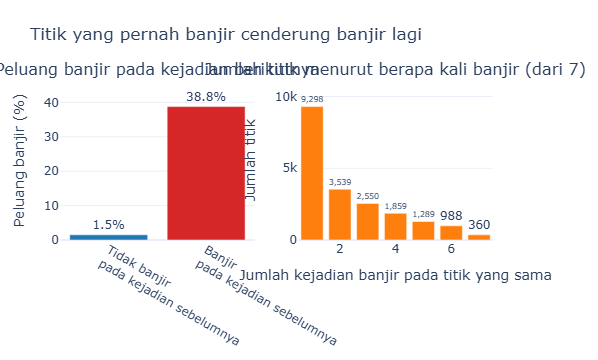

In [20]:

label_prev = {0: "Tidak banjir<br>pada kejadian sebelumnya", 1: "Banjir<br>pada kejadian sebelumnya"}
fig7 = make_subplots(rows=1, cols=2, subplot_titles=(
    "Peluang banjir pada kejadian berikutnya", "Jumlah titik menurut berapa kali banjir (dari 7)"))
fig7.add_trace(go.Bar(
    x=[label_prev[v] for v in persistensi["target_sebelumnya"].to_list()],
    y=persistensi["peluang_banjir_pct"].to_list(),
    text=[f"{v:.1f}%" for v in persistensi["peluang_banjir_pct"].to_list()], textposition="outside",
    marker_color=["#1f77b4", "#d62728"], showlegend=False,
    customdata=persistensi["n_transisi"].to_list(),
    hovertemplate="%{x}<br>Peluang banjir: %{y:.2f}%<br>Jumlah transisi: %{customdata:,}<extra></extra>",
), row=1, col=1)

pernah = dist_rekurensi.filter(pl.col("kejadian_banjir") > 0)
fig7.add_trace(go.Bar(
    x=pernah["kejadian_banjir"].to_list(), y=pernah["n_titik"].to_list(),
    text=[f"{v:,}" for v in pernah["n_titik"].to_list()], textposition="outside",
    marker_color="#ff7f0e", showlegend=False,
    hovertemplate="Banjir %{x} kali<br>Titik: %{y:,}<extra></extra>",
), row=1, col=2)
fig7.update_yaxes(title_text="Peluang banjir (%)", row=1, col=1)
fig7.update_yaxes(title_text="Jumlah titik", row=1, col=2)
fig7.update_xaxes(title_text="Jumlah kejadian banjir pada titik yang sama", row=1, col=2)
fig7.update_layout(title="Titik yang pernah banjir cenderung banjir lagi")
tampilkan(fig7, "eda_07_persistensi_banjir")


Jika sebuah titik banjir pada kejadian sebelumnya, peluang titik itu banjir lagi pada kejadian berikutnya adalah 38,76%, dibanding titik yang sebelumnya tidak banjir, peluangnya 1,50%  (sekitar 25,8 kali lipat). Sebanyak 19.883 titik (13,6%) pernah banjir, 4.496 titik banjir pada empat kejadian atau lebih, dan 360 titik banjir di semua 7 kejadian. Catatan: "kejadian sebelumnya" berarti kejadian sebelumnya dalam data. Selang antar kejadian sangat bervariasi, dari 39 hari sampai sekitar 5,4 tahun.



## Bagian 4: Rumusan Insight Analitik Utama

Enam temuan berikut (melebihi minimal lima) didukung oleh grafik di atas dan angka pada bagian *Angka Pendukung Insight*.

1. **Insight 1 (Tren Waktu & Musiman):**  
   Luas banjir sangat bervariasi antar kejadian dan tidak mengikuti tren maupun musim yang jelas. Kejadian 10 Desember 2003 paling luas (11,83% grid; 17.333 titik), sekitar 2,1 kali kejadian terbesar kedua dan 10 kali yang terkecil (19 Juni 2006, 1,17%). Dua kejadian di bulan Juni berbeda sekitar 4 kali (2006: 1,17%; 2007: 4,84%), sehingga bulan kejadian tidak cukup menjelaskan luas banjir, dan rata-rata hujan 3 hari juga tidak searah dengan luas banjir (korelasi Spearman -0,11, n = 7). *Keterbatasan:* hanya 7 kejadian, sehingga tren tahunan dan pola musiman tidak dapat dipastikan (Visualisasi 1, bagian 2a-2f).

2. **Insight 2 (Distribusi & Anomali):**  
   Banjir hampir seluruhnya terjadi di dataran rendah. Titik dengan elevasi < 10 m hanya 21,7% dari seluruh titik tetapi memuat 77,7% titik banjir; rasio banjir 22,5% pada elevasi 0-5 m dibanding 0,09% pada ≥ 100 m. Pada kemiringan < 0,5° rasio banjir 7,5%, sedangkan pada ≥ 2° hanya 0,07%. Titik banjir juga memiliki NDVI dan NDWI jauh lebih rendah (median NDVI 0,38 vs 0,65; NDWI 0,137 vs 0,260). Pola elevasi ini muncul pada ketujuh kejadian (Visualisasi 2 dan 5).

3. **Insight 3 (Korelasi Kunci):**  
   Tidak ada satu variabel pun yang menjelaskan banjir secara linear, dan hujan bukan penentu utama pada data ini. Korelasi dengan `target`: NDVI -0,24, NDWI -0,21, kemiringan -0,10, elevasi -0,09, hujan hanya 0,03. Hubungan hujan dan banjir juga tidak monoton: rasio banjir memuncak pada hujan 3 hari 60-80 mm (7,93%) lalu turun, dan hanya 1 dari 19.312 titik berhujan ≥ 120 mm yang berlabel banjir (12.891 titik di antaranya dari kejadian 3 Januari 2013). Pada elevasi < 10 m puncaknya 25,86% pada 60-80 mm, sedangkan pada ≥ 100 m rasio rendah berapa pun hujannya. *Hipotesis yang belum diuji:* banjir pada hujan sangat lebat bisa terlewat pada citra (awan), atau data hujan beresolusi kasar. Implikasinya, hujan saja tidak layak dijadikan satu-satunya prediktor (Visualisasi 3 dan 8).

4. **Insight 4 (Perilaku Kategori / Segmen):**  
   Tutupan lahan sangat membedakan kerawanan. Kelas 17 (Water), 11 (Permanent wetland), dan 12 (Cropland) menyumbang 81,7% titik banjir. Rasio banjir tertinggi ada pada kelas 11 (17,79%) dan 17 (17,06%), sedangkan kelas 2 (83.259 titik) dan 8 (142.053 titik) hampir tidak pernah banjir (0,27% dan 0,03%). Cropland berrasio hanya 2,94%, tetapi karena luasnya (275.882 titik) menjadi penyumbang absolut yang besar. Penamaan kelas memakai skema IGBP MODIS sebagai asumsi (Visualisasi 4).

5. **Insight 5 (Pola Spasial & Persistensi):**  
   Banjir terkonsentrasi di sedikit lokasi yang berulang. 44 dari 1.567 sel (2,8%) menampung 50% titik banjir, 109 sel (7,0%) menampung 80%, dan 71,9% sel tidak pernah banjir. Titik yang pernah banjir cenderung banjir lagi: peluangnya 38,76% dibanding 1,50% bila sebelumnya tidak banjir (sekitar 25,8 kali lipat). Ada 19.883 titik (13,6%) yang pernah banjir dan 360 titik yang banjir di semua 7 kejadian. Pusat konsentrasi berada sekitar bujur 119,9-120,0° BT dan lintang 4,0-4,2° LS (Visualisasi 6 dan 7).

6. **Insight 6 (Rekomendasi Praktis):**  
   Berdasarkan seluruh temuan di atas:
   - **Prioritaskan lokasi, bukan hanya waktu.** Pemantauan dan mitigasi sebaiknya difokuskan pada sekitar 109 sel (7% wilayah) yang memuat 80% titik banjir, dimulai dari kawasan inti pada koordinat di atas.
   - **Pakai riwayat banjir sebagai penentu prioritas.** Titik yang pernah banjir punya peluang sekitar 26 kali lebih besar untuk banjir lagi.
   - **Jika membangun model prediksi,** gunakan elevasi, kemiringan, NDVI, NDWI, dan tutupan lahan, bukan hujan saja. Evaluasi per kejadian (satu tanggal sebagai data uji), karena grid titik yang sama pada semua tanggal membuat pembagian acak bocor. Gunakan recall, precision, atau PR-AUC, bukan akurasi, karena hanya sekitar 4,5% titik berlabel banjir.
   - **Verifikasi sebelum dipakai untuk keputusan.** Periksa sumber label banjir, resolusi data hujan, dan skema tutupan lahan pada dokumentasi sumber.

### Keterbatasan Analisis
- Hanya 7 tanggal kejadian dengan selang yang tidak teratur, sehingga tidak ada kesimpulan tentang tren jangka panjang atau musiman.
- Penamaan kelas tutupan lahan memakai skema IGBP MODIS sebagai asumsi.
- Sumber label banjir dan resolusi data hujan belum diverifikasi pada dokumentasi sumber.
- Korelasi Pearson dihitung pada variabel yang miring dan target biner, jadi hanya mengukur hubungan linear.
- Rasio per sel dengan sedikit titik (minimum 7) bisa berisik.
- Hasil menggambarkan asosiasi pada data ini, bukan hubungan sebab-akibat.
